Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset berhasil dimuat! Ukuran data: (4424, 35)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


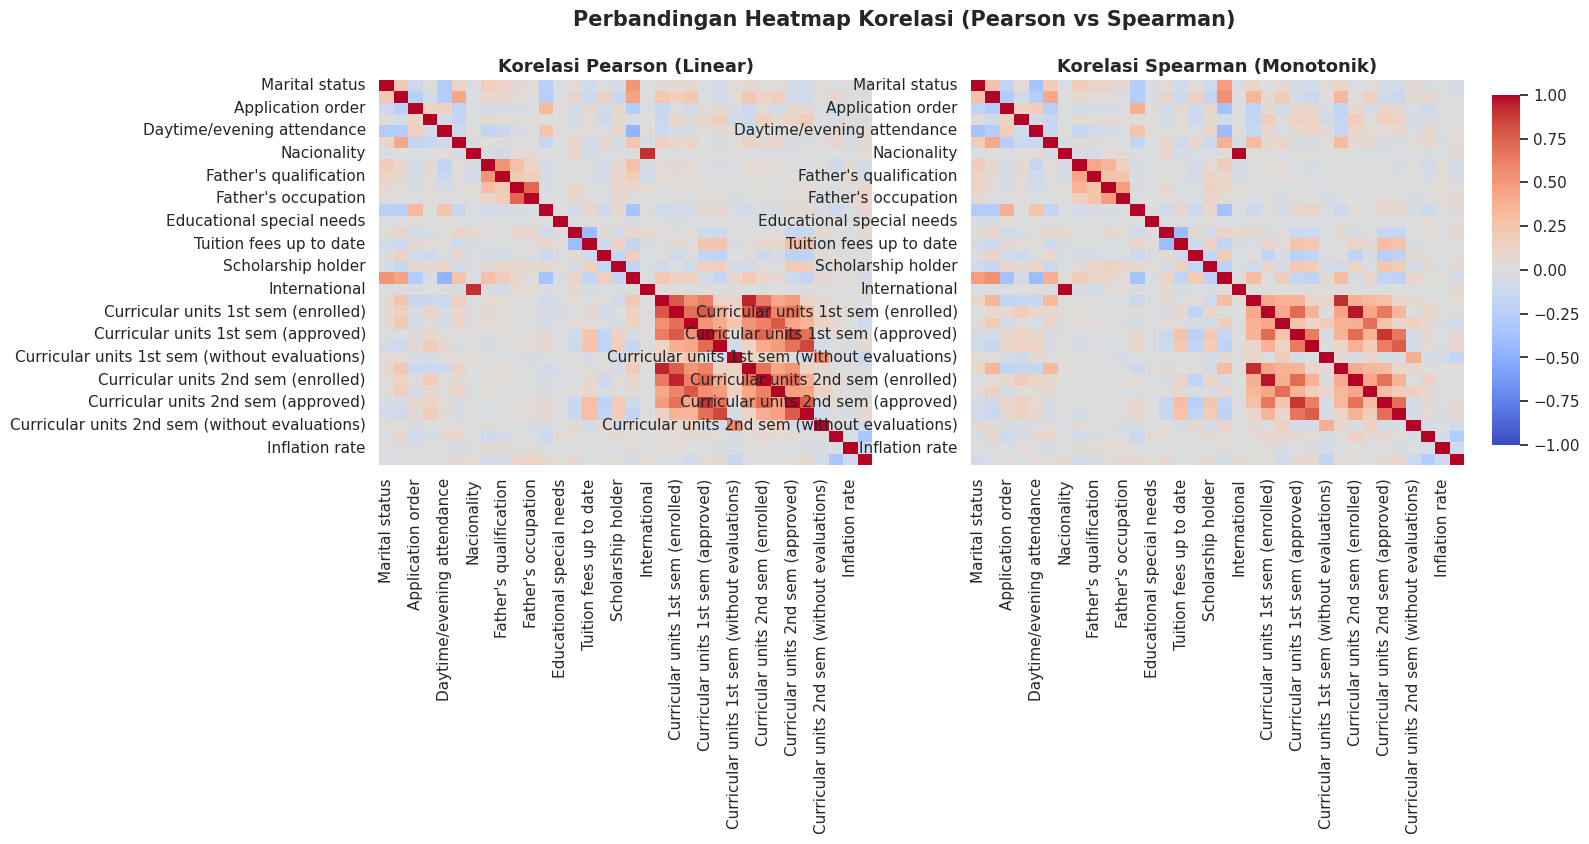

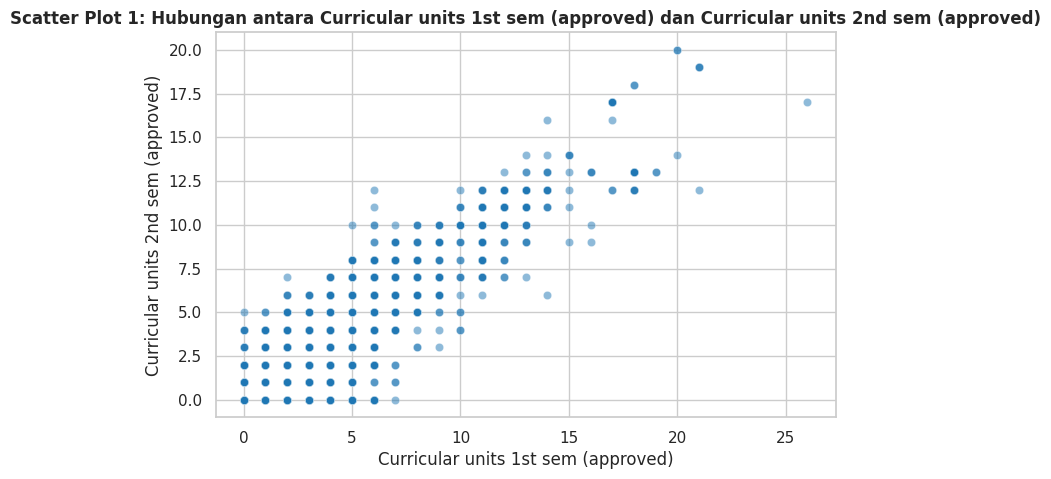

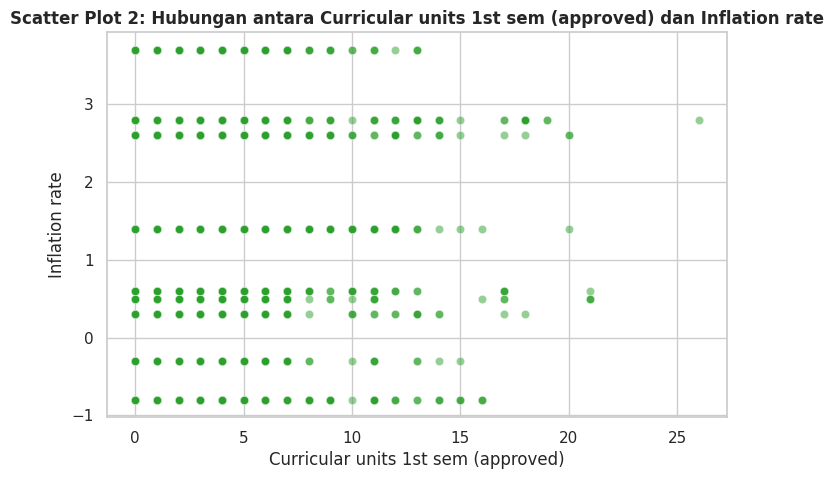

--- Crosstab Dinormalkan per Baris (%) ---
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                     38.71     19.97     41.32
1                     12.19     11.83     75.98

Nilai Cramér's V antara 'Scholarship holder' dan 'Target': 0.3037


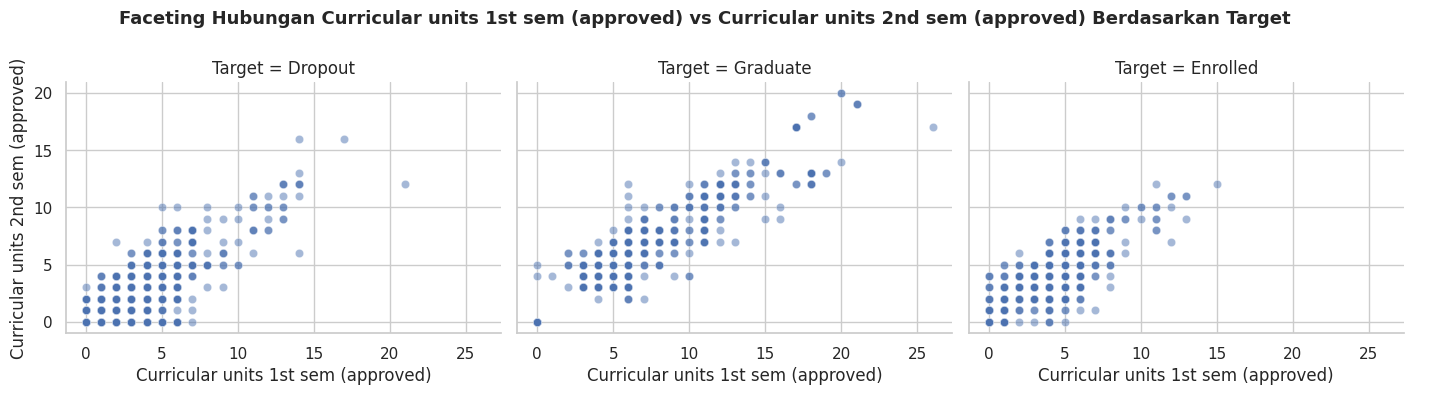

'\nPARAGRAF KANDIDAT VARIABEL PERANCU:\nBerdasarkan analisis hubungan antara SKS lulus semester 1 dan semester 2, salah satu variabel yang berpotensi menjadi variabel perancu\n(confounding variable) adalah tingkat kedisiplinan atau faktor motivasi awal mahasiswa (yang dapat diwakili secara proksi oleh variabel\nseperti nilai seleksi masuk atau status pembayaran uang kuliah). Variabel penunjang ini mempengaruhi performa akademik di kedua semester\nsecara bersamaan. Jika faktor penunjang finansial atau motivasi ini diabaikan, kita mungkin melihat bias dalam menganalisis determinan\nkesuksesan akademik mahasiswa.\n'

In [7]:
# ==========================================
# 0. MOUNT DATASET & IMPORT LIBRARIES
# ==========================================

# --- SKENARIO A: Jika Menggunakan Google Colab ---
# Hapus tanda komentar (#) pada 3 baris di bawah ini jika Anda pakai Colab:
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/praktikum EDA/M3/Copy of dataset.csv'


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Load Dataset dari path yang sudah ditiapkan
# Jika file berbentuk Excel, ganti pd.read_csv menjadi pd.read_excel
df = pd.read_csv(DATA_PATH)

# Menampilkan 5 baris pertama dataset untuk memverifikasi data berhasil dimuat
print("Dataset berhasil dimuat! Ukuran data:", df.shape)
display(df.head())


# ==========================================
# 1. HEATMAP KORELASI (Pearson vs Spearman)
# ==========================================
# Mengambil variabel numerik saja untuk analisis korelasi
num_cols = df.select_dtypes(include=[np.number]).columns

# Hitung matriks korelasi Pearson dan Spearman
corr_pearson = df[num_cols].corr(method='pearson')
corr_spearman = df[num_cols].corr(method='spearman')

# Plot Heatmap berdampingan dengan skala warna sama (vmin=-1, vmax=1, center=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap Pearson
sns.heatmap(corr_pearson, annot=False, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, ax=axes[0], cbar=False)
axes[0].set_title('Korelasi Pearson (Linear)', fontsize=13, fontweight='bold')

# Heatmap Spearman
sns.heatmap(corr_spearman, annot=False, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, ax=axes[1], cbar_ax=fig.add_axes([0.92, 0.15, 0.02, 0.7]))
axes[1].set_title('Korelasi Spearman (Monotonik)', fontsize=13, fontweight='bold')

plt.suptitle('Perbandingan Heatmap Korelasi (Pearson vs Spearman)', fontsize=15, fontweight='bold', y=1.02)
plt.show()


# ==========================================
# 2. DUA SCATTER PLOT & TAFSIRAN
# ==========================================

# Scatter Plot 1: Korelasi Positif Kuat (SKS Lulus Sem 1 vs Sem 2)
var_x1 = 'Curricular units 1st sem (approved)'
var_y1 = 'Curricular units 2nd sem (approved)'

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=var_x1, y=var_y1, color='tab:blue', alpha=0.5)
plt.title(f'Scatter Plot 1: Hubungan antara {var_x1} dan {var_y1}', fontsize=12, fontweight='bold')
plt.xlabel(var_x1)
plt.ylabel(var_y1)
plt.show()

'''
TAFSIRAN SCATTER PLOT 1:
Berdasarkan scatter plot di atas, terlihat adanya pola hubungan linier positif yang sangat kuat antara jumlah SKS yang lulus
di semester 1 dan semester 2. Mahasiswa yang berhasil meluluskan banyak mata kuliah di semester pertama cenderung memiliki
kinerja yang serupa di semester kedua, membentuk pola diagonal yang konsisten.
'''

# Scatter Plot 2: Korelasi Lemah / Tidak Berpola (SKS Lulus Sem 1 vs Inflation rate)
var_x2 = 'Curricular units 1st sem (approved)'
var_y2 = 'Inflation rate'

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=var_x2, y=var_y2, color='tab:green', alpha=0.5)
plt.title(f'Scatter Plot 2: Hubungan antara {var_x2} dan {var_y2}', fontsize=12, fontweight='bold')
plt.xlabel(var_x2)
plt.ylabel(var_y2)
plt.show()

'''
TAFSIRAN SCATTER PLOT 2:
Sebaliknya, scatter plot antara kelulusan mata kuliah dengan tingkat inflasi menunjukkan pola sebaran horizontal
yang acak tanpa ada tren linear maupun non-linear. Hal ini menunjukkan bahwa fluktuasi makroekonomi jangka pendek
(seperti inflasi) tidak berhubungan langsung secara individual dengan jumlah SKS mahasiswa yang lulus pada semester tersebut.
'''


# ==========================================
# 3. CROSSTAB DINORMALKAN PER BARIS & CRAMÉR'S V
# ==========================================
def cramers_v(var1, var2):
    confusion_matrix = pd.crosstab(var1, var2)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1)) / (n-1))
    r_corr = r - ((r-1)**2) / (n-1)
    k_corr = k - ((k-1)**2) / (n-1)
    return np.sqrt(phi2corr / max(0.0001, min((k_corr-1), (r_corr-1))))

# Menggunakan variabel kategorikal nyata
var_kat1 = 'Scholarship holder'
var_kat2 = 'Target'

# Crosstab dinormalkan per baris
crosstab_norm = pd.crosstab(df[var_kat1], df[var_kat2], normalize='index') * 100
print("--- Crosstab Dinormalkan per Baris (%) ---")
print(crosstab_norm.round(2))

# Hitung Cramér's V
v_val = cramers_v(df[var_kat1], df[var_kat2])
print(f"\nNilai Cramér's V antara '{var_kat1}' dan '{var_kat2}': {v_val:.4f}")


# ==========================================
# 4. FACETING DARI SCATTER PLOT
# ==========================================
# Melakukan faceting visualisasi korelasi berdasarkan status kelulusan
g = sns.FacetGrid(df, col=var_kat2, height=4, aspect=1.2)
g.map_dataframe(sns.scatterplot, x=var_x1, y=var_y1, alpha=0.5)
g.add_legend()
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle(f'Faceting Hubungan {var_x1} vs {var_y1} Berdasarkan {var_kat2}', fontsize=13, fontweight='bold')
plt.show()

'''
KETERANGAN PATTERN (POLA FACETING):
Setelah dilakukan faceting berdasarkan variabel 'Target' (Dropout, Graduate, Enrolled), terlihat pola kelulusan SKS yang kontras.
Pada kelompok 'Graduate', titik-titik data berkonsentrasi sangat padat di ujung kanan atas (menandakan kelulusan SKS yang tinggi
di kedua semester). Sedangkan kelompok 'Dropout' menumpuk di sisi kiri bawah, di mana banyak mahasiswa tidak lulus satu mata kuliah pun
di semester 1 maupun semester 2.
'''


# ==========================================
# 5. KANDIDAT VARIABEL PERANCU (CONFOUNDING VARIABLE)
# ==========================================
'''
PARAGRAF KANDIDAT VARIABEL PERANCU:
Berdasarkan analisis hubungan antara SKS lulus semester 1 dan semester 2, salah satu variabel yang berpotensi menjadi variabel perancu
(confounding variable) adalah tingkat kedisiplinan atau faktor motivasi awal mahasiswa (yang dapat diwakili secara proksi oleh variabel
seperti nilai seleksi masuk atau status pembayaran uang kuliah). Variabel penunjang ini mempengaruhi performa akademik di kedua semester
secara bersamaan. Jika faktor penunjang finansial atau motivasi ini diabaikan, kita mungkin melihat bias dalam menganalisis determinan
kesuksesan akademik mahasiswa.
'''